# 🚚 Olist E-Ticaret: Bölgesel Sipariş ve Lojistik Performans Analizi

## 📋 Proje Özeti ve Amaç
Bu proje, Brezilya'daki Olist e-ticaret platformuna ait halka açık sipariş verilerini kullanarak bölgesel sipariş yoğunluğu, sipariş değerleri ve lojistik teslimat sürelerini analiz etmek amacıyla hazırlanmıştır.

Analiz şu 4 temel iş sorusuna odaklanmaktadır:
1. Hangi eyaletler en yüksek sipariş hacmini yaratıyor?
2. Eyaletler arasında ortalama sipariş değeri (Order Value) nasıl değişiyor?
3. Hangi eyaletler en uzun teslimat sürelerine sahip?
4. En hızlı ve en yavaş eyaletler arasındaki lojistik performans farkı kaç gündür?

- Proje ilk olarak **VBO AI & Data Summer Camp 2026** kapsamında tamamlanmış olup, burada portföy odaklı bir analitik vaka çalışması olarak yeniden düzenlenmiştir.

### Amaç

Ek bir PostgreSQL depolama adımıyla birlikte Python ve Pandas kullanarak e-ticaret işlem verilerini net ve tekrarlanabilir iş içgörülerine dönüştürmektir.

### Teknoloji Yığını (Tech Stack)

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook / Google Colab
- PostgreSQL
- SQLAlchemy
- Neon PostgreSQL

## Veri Yükleme ve Ön İşleme

### Veri Kaynakları

Analiz üç Olist tablosunu kullanmaktadır:

- `olist_orders_dataset.csv` — sipariş yaşam döngüsü ve zaman damgaları
- `olist_order_items_dataset.csv` — ürünler, fiyatlar ve kargo ücretleri
- `olist_customers_dataset.csv` — müşteri konum bilgileri

Veriler doğrudan halka açık VBO Summer Camp deposundan yüklenmektedir.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Görselleştirme standartları
plt.rcParams["figure.figsize"] = (10, 5)

RAW_BASE = "https://raw.githubusercontent.com/cemalcici/vbo-summer-camp-2026/main/data"

# Veri setlerinin yüklenmesi
orders = pd.read_csv(
    f"{RAW_BASE}/olist_orders_dataset.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_delivered_customer_date"
    ]
)

order_items = pd.read_csv(
    f"{RAW_BASE}/olist_order_items_dataset.csv"
)

customers = pd.read_csv(
    f"{RAW_BASE}/olist_customers_dataset.csv"
)

print(f"Sipariş Sayısı: {orders.shape[0]:,}")
print(f"Sipariş Kalemi Sayısı: {order_items.shape[0]:,}")
print(f"Müşteri Sayısı: {customers.shape[0]:,}")

Sipariş Sayısı: 99,441
Sipariş Kalemi Sayısı: 112,650
Müşteri Sayısı: 99,441


## 1. Pazar Geneli ve Ürün Metrikleri (Ön Analiz)
### 1.1 Pazarın coğrafi dağılımını ve aktif eyalet çeşitliliğini analiz etme.

In [2]:
# En çok siparişin geldiği eyalet
siparis_musteri = orders.merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')
Max_siparis = siparis_musteri['customer_state'].value_counts().index[0]
Max_siparis

'SP'

In [3]:
# Aktif eyalet sayısı ve en yüksek ürün fiyatı
total_states = customers['customer_state'].nunique()
max_product_price = order_items['price'].max()

print(f"Aktif Müşteri Bulunan Eyalet Sayısı: {total_states}")
print(f"Katalogdaki En Yüksek Ürün Fiyatı: R$ {max_product_price:,.2f}")

Aktif Müşteri Bulunan Eyalet Sayısı: 27
Katalogdaki En Yüksek Ürün Fiyatı: R$ 6,735.00


## 2. Bölgesel Sipariş Yoğunluğu Analizi

💡 **İş Sorusu**:
En yüksek sipariş sayısını hangi Brezilya eyaletleri oluşturmaktadır?

Müşteri ve sipariş tabloları `customer_id` üzerinden birleştirilmiştir.

In [4]:
# Eyalet bazında sipariş sayıları
orders_by_state = (
    orders
    .merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')
    .groupby('customer_state')
    .size()
    .sort_values(ascending=False)
    .reset_index(name='order_count')
)

top_state = orders_by_state.iloc[0]['customer_state']
print(f"En Yüksek Hacimli Eyalet: {top_state}")
display(orders_by_state.head(10))

En Yüksek Hacimli Eyalet: SP


,customer_state,order_count
0,SP,41746
1,RJ,12852
2,MG,11635
3,RS,5466
4,PR,5045
5,SC,3637
6,BA,3380
7,DF,2140
8,ES,2033
9,GO,2020


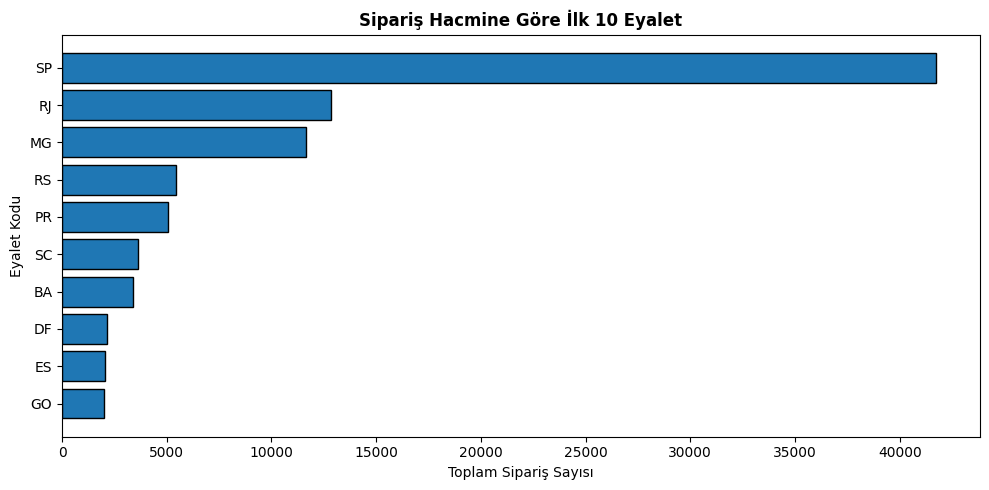

In [5]:
# Görselleştirme: İlk 10 Eyalet
plt.figure(figsize=(10, 5))
top10_orders = orders_by_state.head(10).sort_values('order_count', ascending=True)

plt.barh(top10_orders['customer_state'], top10_orders['order_count'], color='#1f77b4', edgecolor='black')
plt.title('Sipariş Hacmine Göre İlk 10 Eyalet', fontsize=12, fontweight='bold')
plt.xlabel('Toplam Sipariş Sayısı')
plt.ylabel('Eyalet Kodu')
plt.tight_layout()
plt.show()

💡 **İş İçgörüsü**
> Eyaletler arasında ortalama sipariş değeri ve teslimat süreleri açısından belirgin farklılıklar görülmektedir. Ancak bu farklılıkların müşteri davranışı, kargo maliyeti veya lojistik altyapı gibi belirli faktörlerden kaynaklandığı mevcut analiz kapsamında doğrulanmamıştır.

## 3. Genel Teslimat Süreleri ve SLA Analizi

Teslimat süresi, aşağıdaki iki tarih arasındaki takvim günü sayısı olarak tanımlanmıştır:

- `order_purchase_timestamp` (Sipariş Satın Alma Zamanı)
- `order_delivered_customer_date` (Müşteriye Teslim Tarihi)

Teslimat süresi analizine yalnızca müşteri teslimat zaman damgası boş (null) olmayan siparişler dahil edilmiştir.

Sipariş değeri yalnızca `price` (fiyat) alanından hesaplanmıştır; orijinal analiz tanımıyla tutarlı kalmak adına `freight_value` (kargo bedeli) hariç tutulmuştur.

In [6]:
# Teslim edilmiş siparişlerin seçilmesi
delivered_orders = orders.dropna(
    subset=["order_delivered_customer_date"]
).copy()

# Teslimat süresinin gün cinsinden hesaplanması
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.days

# Teslimat süresi metrikleri
median_delivery = delivered_orders["delivery_days"].median()
p90_delivery = delivered_orders["delivery_days"].quantile(0.90)

print(f"Medyan Teslimat Süresi: {median_delivery:.0f} gün")
print(f"P90 Teslimat Süresi: {p90_delivery:.0f} gün")

Medyan Teslimat Süresi: 10 gün
P90 Teslimat Süresi: 23 gün


In [7]:
# Siparişleri müşteri eyalet bilgisiyle birleştirme
delivered_by_state = (
    delivered_orders
    .merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
)

# Eyalet bazında teslimat performansı
state_delivery_perf = (
    delivered_by_state
    .groupby("customer_state")
    .agg(
        order_count=("order_id", "count"),
        avg_delivery_days=("delivery_days", "mean")
    )
    .sort_values("avg_delivery_days", ascending=False)
)

# En yavaş ve en hızlı eyalet arasındaki fark
slowest_state = state_delivery_perf.index[0]
fastest_state = state_delivery_perf.index[-1]

slowest_delivery = state_delivery_perf.iloc[0]["avg_delivery_days"]
fastest_delivery = state_delivery_perf.iloc[-1]["avg_delivery_days"]

delivery_gap = slowest_delivery - fastest_delivery

print(f"En Yavaş Eyalet: {slowest_state}")
print(f"En Hızlı Eyalet: {fastest_state}")
print(f"Teslimat Süresi Farkı: {delivery_gap:.2f} gün")

En Yavaş Eyalet: RR
En Hızlı Eyalet: SP
Teslimat Süresi Farkı: 20.68 gün


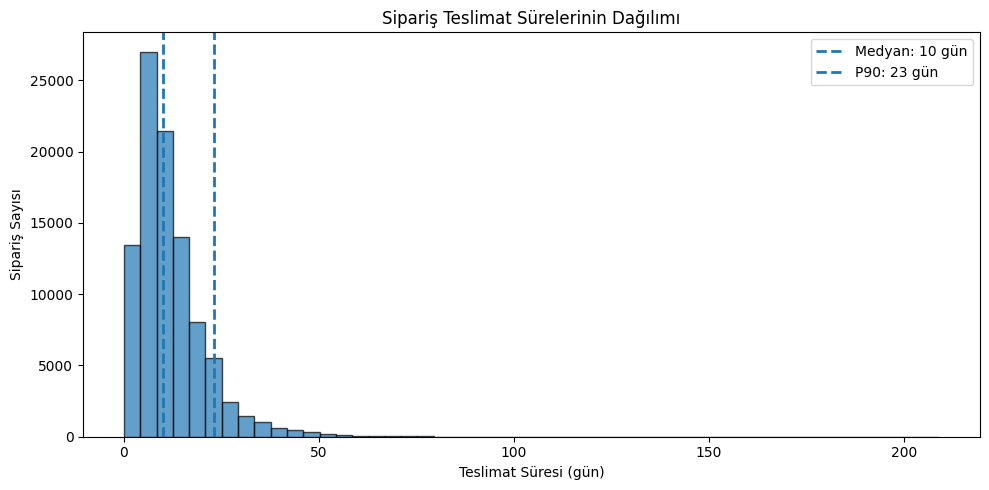

In [8]:
# Teslimat süresi dağılımı
plt.figure(figsize=(10, 5))

plt.hist(
    delivered_orders["delivery_days"],
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    median_delivery,
    linestyle="--",
    linewidth=2,
    label=f"Medyan: {median_delivery:.0f} gün"
)

plt.axvline(
    p90_delivery,
    linestyle="--",
    linewidth=2,
    label=f"P90: {p90_delivery:.0f} gün"
)

plt.title("Sipariş Teslimat Sürelerinin Dağılımı")
plt.xlabel("Teslimat Süresi (gün)")
plt.ylabel("Sipariş Sayısı")
plt.legend()
plt.tight_layout()
plt.show()

### 3.1. Genel Teslimat Performansı

Teslimat performansını değerlendirmek için iki temel istatistik kullanılmıştır:

- **Medyan:** Tipik bir siparişin teslim edilmesi için geçen süreyi gösterir.
- **P90:** Teslimat sürelerinin üst %10'luk bölümünü anlamaya yardımcı olur ve uzun süren teslimatların operasyonel etkisini değerlendirmek için kullanılır.

Bu iki metrik birlikte değerlendirildiğinde yalnızca ortalama performans değil, teslimat süresinin dağılımındaki uzun kuyruk da görülebilir.

## 4. Eyalet Bazında Lojistik Performans Farkı ve Ortalama Sipariş Değeri (AOV)

In [9]:
# `state_delivery_perf`, 3. bölümde hesaplandığı için burada yeniden oluşturulmadan kullanılır.

# Sipariş başına toplam ürün değeri
order_values = (
    order_items
    .groupby("order_id")["price"]
    .sum()
    .reset_index(name="order_value")
)

# Eyalet bazında ortalama sipariş değeri
state_aov = (
    order_values
    .merge(
        orders[["order_id", "customer_id"]],
        on="order_id",
        how="left"
    )
    .merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left"
    )
    .groupby("customer_state")
    .agg(
        avg_order_value=("order_value", "mean")
    )
    .sort_values("avg_order_value", ascending=False)
)

print("\nEn Yüksek Ortalama Sipariş Değerine Sahip İlk 5 Eyalet:")
display(state_aov.head(5))

# Ortalama teslimat süresi en uzun ilk 5 eyalet
top_5_slowest_states = state_delivery_perf.head(5)

print("Ortalama teslimat süresi en uzun ilk 5 eyalet:")
display(
    top_5_slowest_states[
        ["order_count", "avg_delivery_days"]
    ]
)


En Yüksek Ortalama Sipariş Değerine Sahip İlk 5 Eyalet:


,avg_order_value
customer_state,
PB,216.669323
AP,198.151471
AC,197.320370
AL,195.413163
RO,186.804211


Ortalama teslimat süresi en uzun ilk 5 eyalet:


,order_count,avg_delivery_days
customer_state,,
RR,41,28.975610
AP,67,26.731343
AM,145,25.986207
AL,397,24.040302
PA,946,23.316068


## 5. PostgreSQL ile Veri Tabanı Entegrasyonu

Analiz çıktısının PostgreSQL'de saklanabilmesi için SQLAlchemy ve Pandas `to_sql()` kullanılarak isteğe bağlı bir aktarım adımı hazırlanmıştır.

Aktarımın gerçekleşmesi için çalışma ortamında `DATABASE_URL` adlı ortam değişkeninin tanımlanması ve geçerli bir PostgreSQL bağlantı adresi içermesi gerekir. Bağlantı bilgileri kod içine veya GitHub deposuna yazılmamalıdır; ortam değişkenleri ya da Google Colab Secrets gibi güvenli yöntemlerle yönetilmelidir.

> **Çalıştırma durumu:** Bu notebook'un kayıtlı çalıştırmasında `DATABASE_URL` tanımlı olmadığından PostgreSQL'e veri aktarılmamıştır. Dolayısıyla bu bölüm, tamamlanmış bir veritabanı yüklemesini değil, bağlantı yapılandırıldığında çalıştırılabilecek entegrasyon akışını göstermektedir.


In [10]:
# PostgreSQL bağlantısı için gerekli kütüphaneler
# Gerekirse:
# !pip install sqlalchemy psycopg2-binary

from sqlalchemy import create_engine
import os

# Güvenlik nedeniyle bağlantı bilgisini kod içerisinde saklamıyoruz.
DATABASE_URL = os.getenv("DATABASE_URL")

if DATABASE_URL:
    engine = create_engine(DATABASE_URL)

    state_delivery_perf.to_sql(
        "olist_state_delivery_performance",
        engine,
        if_exists="replace",
        index=True
    )

    print("Eyalet bazlı teslimat performansı PostgreSQL'e aktarıldı.")
else:
    print(
        "DATABASE_URL tanımlı olmadığı için PostgreSQL aktarımı "
        "çalıştırılmadı."
    )

DATABASE_URL tanımlı olmadığı için PostgreSQL aktarımı çalıştırılmadı.


## 6. İş Perspektifinden Değerlendirme

Analiz sonuçları yalnızca istatistiksel metrikler olarak değil, operasyonel kararlar açısından da değerlendirilmiştir.

### 6.1 Sipariş hacmi ile teslimat performansı birlikte nasıl değerlendirilmelidir?

Yüksek sipariş hacmine sahip eyaletler operasyonel açıdan daha yüksek öneme sahiptir. Ancak yüksek hacim tek başına iyi veya kötü performans anlamına gelmez.

Bu nedenle bölgesel performans değerlendirmesinde:

- Sipariş hacmi
- Ortalama teslimat süresi
- P90 teslimat süresi
- Ortalama sipariş değeri

gibi göstergelerin birlikte incelenmesi daha anlamlıdır.

### 6.2 Medyan ve P90 neden birlikte kullanılmalıdır?

Medyan tipik teslimat deneyimini gösterirken P90, uzun süren teslimatların etkisini ortaya çıkarmaya yardımcı olur.

Örneğin medyan teslimat süresi kabul edilebilir seviyede olsa bile P90 değerinin yüksek olması, siparişlerin belirli bir bölümünde ciddi gecikmeler yaşandığını gösterebilir.

Bu nedenle yalnızca ortalamaya veya medyana bakmak operasyonel risklerin tamamını göstermeyebilir.

### 6.3 Eyaletler arasındaki teslimat farklarının olası nedenleri nelerdir?

Veri setinde eyaletler arasında belirgin teslimat süresi farklılıkları görülmektedir.

Bu farklılıkların olası açıklamaları arasında:

- Coğrafi mesafe
- Lojistik altyapı
- Dağıtım merkezlerine erişim
- Bölgesel taşıma koşulları
- Sipariş yoğunluğu
- Teslimat ağının yapısı

bulunabilir.

Ancak mevcut analiz bu faktörlerin neden-sonuç ilişkisini test etmemektedir. Bu nedenle bunlar doğrulanmış nedenler değil, ileri analiz için değerlendirilebilecek hipotezlerdir.

### 6.4 Analiz sonucunda hangi operasyonel aksiyonlar değerlendirilebilir?

Analiz sonuçları doğrultusunda aşağıdaki çalışmalar yapılabilir:

- Yüksek sipariş hacmine sahip eyaletlerde teslimat SLA'larının yakından izlenmesi
- Teslimat süresi yüksek bölgelerin ayrıca incelenmesi
- P90 seviyesindeki uzun teslimatların nedenlerinin araştırılması
- Yüksek sipariş değerine sahip bölgelerde müşteri davranışlarının analiz edilmesi
- Eyalet bazlı KPI'ların Power BI gibi bir BI aracı üzerinden takip edilmesi

## 7. Yönetici Özeti (Executive Summary) ve Sonuç (Conclusion)

Bu çalışma, Olist e-ticaret verileri üzerinden bölgesel sipariş hacmi, teslimat performansı ve ortalama sipariş değeri arasındaki farklılıkları incelemektedir.

Analiz sonucunda:

- 27 farklı müşteri eyaleti gözlemlenmiştir.
- São Paulo (SP) en yüksek sipariş hacmine sahip eyalettir.
- Medyan teslimat süresi 10 gündür.
- P90 teslimat süresi 23 gündür.
- Teslim edilen sipariş hacminde SP, RJ ve MG öne çıkmaktadır.
- Eyaletler arasında ortalama teslimat sürelerinde yaklaşık 20,68 günlük fark bulunmaktadır.

>En hızlı ve en yavaş eyalet arasındaki yaklaşık **20,68 günlük teslimat süresi farkı**, bölgesel lojistik performansın ayrıca incelenmesi gereken bir alan olduğunu göstermektedir.
> Bu farklılıkların nedenlerini ortaya koymak için mesafe, kargo maliyeti, sipariş yoğunluğu ve lojistik ağ yapısı gibi ek değişkenlerle ileri analiz yapılabilir.

Bu rakamlar incelenen veri setini tanımlamaktadır; tek başlarına bölgesel farklılıklar için nedensel açıklamalar oluşturmazlar.

Çalışmanın temel çıktısı, bölgesel performansın tek bir KPI üzerinden değerlendirilmemesi gerektiğini göstermektedir. Sipariş hacmi, teslimat süresi, P90 ve sipariş değeri birlikte incelendiğinde operasyonel performans hakkında daha kapsamlı bir görünüm elde edilebilir.

### Gelecek Çalışmalar

Analiz aşağıdaki çalışmalarla genişletilebilir:

- Teslimat gecikmesinin tahmin edilmesi
- Bölgesel lojistik kümelerinin oluşturulması
- Sipariş değerinin müşteri segmentlerine göre incelenmesi
- Teslimat performansının ürün kategorileriyle ilişkilendirilmesi
- PostgreSQL üzerinde daha kapsamlı analitik tablolar oluşturulması
- Power BI dashboard'u ile KPI takibi